© 2026 by Tamás Takács is licensed under CC BY-NC-SA 4.0. To view a copy of this license, visit https://creativecommons.org/licenses/by-nc-sa/4.0/

# **First Network (SOLUTION)**

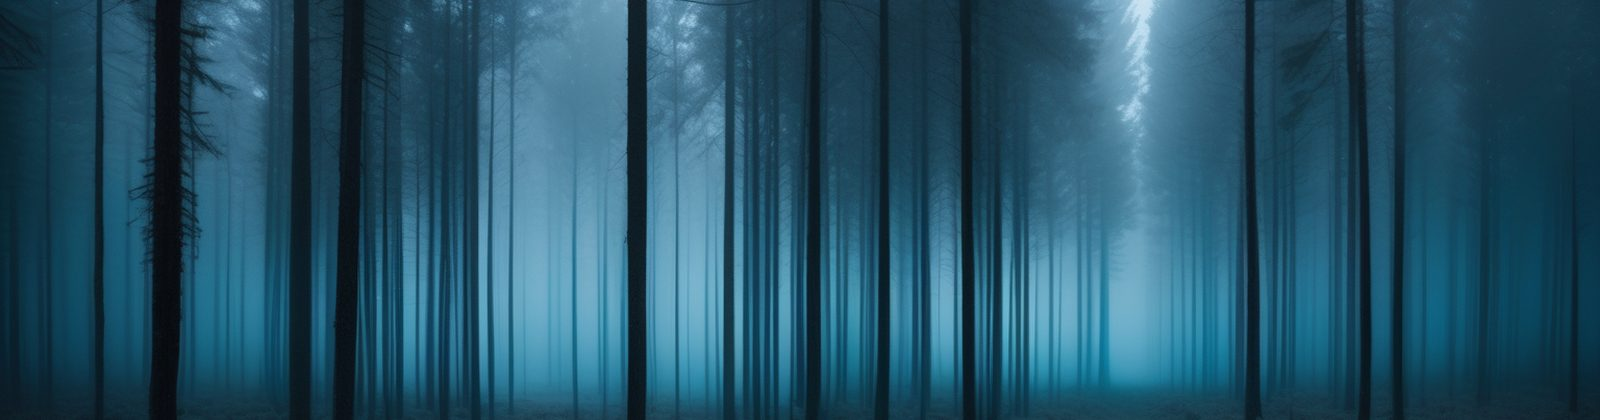

## **Task overview**

A customer register in which each row is a customer and `churn` records whether they left. The task is to predict `churn` from the other columns.

| Part | Task | Points |
|---|---|---:|
| a | The preprocessing, checked number by number | 30 |
| b | Churn predictions for an unlabelled test set | 35 |
| c | The same model, on a second cohort | 35 |

Part a is arithmetic and has exactly one right answer. Parts b and c are graded on how many of your predictions are correct, so partial credit is continuous: a model that is right 70% of the time scores about 70% of the marks.

**Both test sets are class balanced.** Half the rows churned and half did not, so submitting all zeros scores 50%, against about 64% at the natural churn rate of 36%.



## **The preprocessing recipe**

Part a only has one right answer because the recipe is fixed. Follow it exactly, in this order, and use it for parts b and c too.

1. **Imputation.** Replace every missing numeric value with the **median of that column in `train.csv`**. Compute the median ignoring the missing values. Use the *training* median everywhere, including on the test files: nothing computed from a test file goes into the preprocessing.
2. **Standardisation.** Subtract the mean and divide by the standard deviation, both computed on the **training** columns **after** imputing, both population statistics (divide by the count, not the count minus one).
3. **One-hot encoding.** Encode the three categorical columns, in the order `region`, `plan`, `channel`, and within each in the order: `North, Harbour, Midland, Eastfield, Southgate, Upland`; `basic, standard, premium, legacy`; `shop, phone, online`.
4. **Concatenation.** Place the four standardised numeric columns first, then the one-hot blocks in that order. That gives **17 columns**.

**Part a, 20 rows.**

- row `0`: how many rows are in `train.csv`
- row `1`: how many rows are in `test.csv`
- row `2`: how many feature columns after step 4
- rows `3..6`: the imputation median of `age`, `income`, `tenure_months`, `score`, times 100
- rows `7..10`: the training mean of each numeric column after imputing, times 100
- rows `11..14`: the training standard deviation of each, times 100
- rows `15..19`: the standardised value at these positions of the training matrix, times 100, in this order: `(0, 0)`, `(5, 1)`, `(17, 2)`, `(123, 3)`, `(999, 0)`, where the first number is the row of `train.csv` in file order and the second is the column index from step 4.

**Part b, one row per row of `test.csv`, in file order.** Report `1` if you predict the customer churned and `0` if not.

**Part c, one row per row of `cohort2.csv`, in file order.** The same model, no retraining, applied to a completely separate draw of customers. Use the **training** medians, mean and standard deviation here too.

## **The reference network**

The reference network below scores between 65% and 70% on the test set. A different architecture is allowed.

`Linear(17, 32)` then ReLU, `Linear(32, 16)` then ReLU, `Linear(16, 1)`. Loss `BCEWithLogitsLoss`, optimiser Adam at learning rate `0.001`, 40 epochs, batch size 128. Predict churn when the sigmoid of the output is above `0.5`.

## **Useful Links**

- [`torch.nn` module reference](https://pytorch.org/docs/stable/nn.html)
- [`nn.BCEWithLogitsLoss`](https://pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html)
- [Optimizers](https://pytorch.org/docs/stable/optim.html)
- [Tensors from NumPy](https://pytorch.org/docs/stable/generated/torch.from_numpy.html)

## **Setup and data**

In [ ]:
# ══════════════════════════════════════════════════════════
# Setup. DO NOT MODIFY.
# ══════════════════════════════════════════════════════════
import csv
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn

torch.manual_seed(42)
np.random.seed(42)

def write_submission(filename, rows):
    """Write [(id, target), ...] as a DOCK-ready CSV."""
    with open(filename, "w", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        writer.writerow(["id", "target"])
        for row_id, target in rows:
            writer.writerow([int(row_id), int(target)])
    print(f"wrote {filename}: {len(rows)} rows")

def _find(name):
    here = Path(name)
    return here if here.exists() else Path("data") / name

def load(name):
    with open(_find(name), newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))

NUMERIC = ["age", "income", "tenure_months", "score"]
CATEGORICAL = ["region", "plan", "channel"]
CATEGORIES = {
    "region": ["North", "Harbour", "Midland", "Eastfield", "Southgate", "Upland"],
    "plan": ["basic", "standard", "premium", "legacy"],
    "channel": ["shop", "phone", "online"],
}

train = load("train.csv")
test = load("test.csv")
cohort2 = load("cohort2.csv")

print(f"train {len(train)} rows (with churn), test {len(test)}, cohort2 {len(cohort2)}")
print("train columns:", list(train[0]))
print("churn rate in train:", sum(int(r["churn"]) for r in train) / len(train))

---
## **Part a: The preprocessing (30 points)**

Part a checks the preprocessing before any network is trained: the row counts, the training statistics and five entries of the training matrix.

Submission: `part1_submission.csv`, 20 rows, uploaded to part a.

In [ ]:
def column(records, name):
    return np.array([float(r[name]) if r[name] != "" else np.nan for r in records])

# 1. impute with the TRAINING median
medians = {c: float(np.nanmedian(column(train, c))) for c in NUMERIC}

def numeric_block(records):
    cols = []
    for c in NUMERIC:
        v = column(records, c)
        cols.append(np.where(np.isnan(v), medians[c], v))
    return np.stack(cols, axis=1)

num_train = numeric_block(train)
mean, std = num_train.mean(axis=0), num_train.std(axis=0)     # 2. training stats

def features(records):
    x = (numeric_block(records) - mean) / std
    blocks = [x]
    for cat in CATEGORICAL:                                    # 3. one-hot, in order
        v = np.array([r[cat] for r in records])
        blocks.append(np.stack([(v == lv).astype(float) for lv in CATEGORIES[cat]], axis=1))
    return np.concatenate(blocks, axis=1)                      # 4. concatenate

xtr, xte, x2 = features(train), features(test), features(cohort2)
ytr = np.array([float(r["churn"]) for r in train])

part1 = [(0, len(train)), (1, len(test)), (2, xtr.shape[1])]
k = 3
for c in NUMERIC:
    part1.append((k, int(round(medians[c] * 100)))); k += 1
for v in mean:
    part1.append((k, int(round(float(v) * 100)))); k += 1
for v in std:
    part1.append((k, int(round(float(v) * 100)))); k += 1
for r, c in [(0, 0), (5, 1), (17, 2), (123, 3), (999, 0)]:
    part1.append((k, int(round(float(xtr[r, c]) * 100)))); k += 1

write_submission("part1_submission.csv", part1)
part1

---
## **Part b: Train it (35 points)**

Build the network, train it on `train.csv`, and predict for every row of `test.csv` in file order.

Write the training loop yourself: shuffle the rows, walk them in batches, zero the gradients, forward, loss, backward, step. That is about five lines inside two loops, one over epochs and one over batches.

Submission: `part2_submission.csv`, one row per test row, uploaded to part b.

In [ ]:
class Net(nn.Module):
    def __init__(self, n_in):
        super().__init__()
        self.stack = nn.Sequential(
            nn.Linear(n_in, 32), nn.ReLU(),
            nn.Linear(32, 16), nn.ReLU(),
            nn.Linear(16, 1))

    def forward(self, x):
        return self.stack(x).squeeze(-1)

torch.manual_seed(42)
net = Net(xtr.shape[1])
opt = torch.optim.Adam(net.parameters(), lr=1e-3)
loss_fn = nn.BCEWithLogitsLoss()

x = torch.tensor(xtr, dtype=torch.float32)
y = torch.tensor(ytr, dtype=torch.float32)
g = torch.Generator().manual_seed(42)
for epoch in range(40):
    perm = torch.randperm(len(x), generator=g)
    for i in range(0, len(x), 128):
        b = perm[i:i + 128]
        opt.zero_grad()
        loss = loss_fn(net(x[b]), y[b])
        loss.backward()
        opt.step()
    if epoch % 10 == 9:
        print(f"epoch {epoch + 1:>3}  last batch loss {loss.item():.4f}")

def predict(matrix):
    with torch.no_grad():
        logits = net(torch.tensor(matrix, dtype=torch.float32))
        return (torch.sigmoid(logits) > 0.5).long().numpy()

part2 = [(i, int(v)) for i, v in enumerate(predict(xte))]

write_submission("part2_submission.csv", part2)
part2[:8]

---
## **Part c: A second cohort (35 points)**

`cohort2.csv` is a separate group of customers, drawn from the same process as the other two files and not part of either. **Do not retrain.** Use the model you already have, and the medians, mean and standard deviation you computed from the training set.

Because the two files come from the same process, a model scores about the same on both: the reference network's two accuracies differ by less than two percentage points.

Submission: `part3_submission.csv`, one row per cohort2 row, uploaded to part c.

In [ ]:
part3 = [(i, int(v)) for i, v in enumerate(predict(x2))]

write_submission("part3_submission.csv", part3)
part3[:8]

---
## **Submission**

Upload each CSV to its own part on DOCK.

